## 1. Generate Data and Plot Scatter

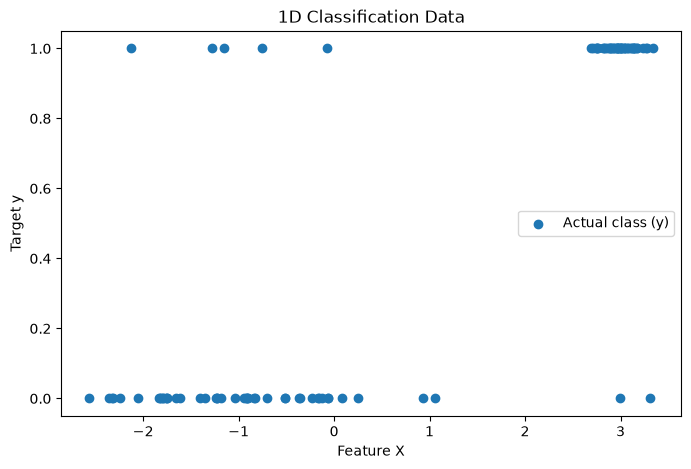

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression

X, y = make_classification(
    n_samples=100,
    n_features=1,
    n_informative=1,
    n_redundant=0,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=1,
    weights=[0.5, 0.5],
    flip_y=0.15,
    class_sep=2.0,
    hypercube=True,
    shift=1.0,
    scale=1.0,
    shuffle=True,
    random_state=88
)

X_1d = X.reshape(1, -1)[0]

plt.figure(figsize=(8, 5))
plt.scatter(X_1d, y, label="Actual class (y)")
plt.xlabel("Feature X")
plt.ylabel("Target y")
plt.title("1D Classification Data")
plt.legend()
plt.show()


## 2. Fit Model and Plot Fitted Sigmoid Curve

In [5]:
clf = LogisticRegression()
clf.fit(X, y)

coef = clf.coef_[0][0]
intercept = clf.intercept_[0]


print(f"Coefficient: {coef:.4f}")
print(f"Intercept: {intercept:.4f}")



Coefficient: 1.1889
Intercept: -0.9850


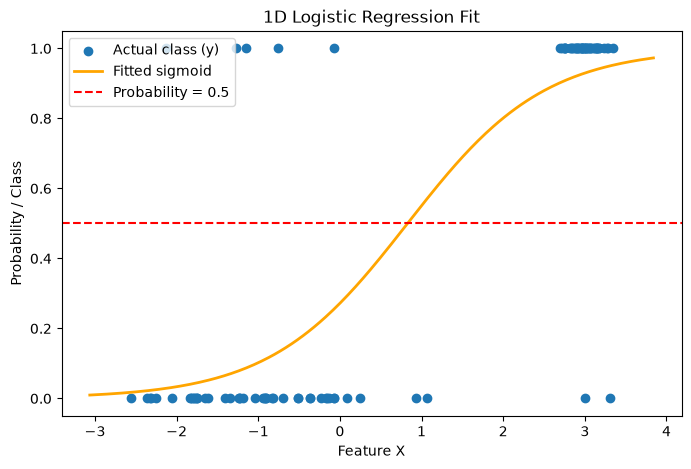

In [9]:
# Create smooth x values to draw the continuous sigmoid curve
x_vals = np.linspace(X_1d.min() - 0.5, X_1d.max() + 0.5, 300)
sigmoid_vals = 1 / (1 + np.exp(-(coef * x_vals + intercept)))

plt.figure(figsize=(8, 5))
plt.scatter(X_1d, y, label="Actual class (y)")
plt.plot(x_vals, sigmoid_vals, color="orange", linewidth=2, label="Fitted sigmoid")
plt.axhline(y=0.5, color="red", linestyle="--", label="Probability = 0.5")
plt.xlabel("Feature X")
plt.ylabel("Probability / Class")
plt.title("1D Logistic Regression Fit")
plt.legend()
plt.show()


## 3. Implement predict_probability and predict_class

In [10]:
def predict_probability(coefs, X):
    coef, intercept = coefs
    X_flat = np.asarray(X).reshape(-1)
    probabilities = 1 / (1 + np.exp(-(coef * X_flat + intercept)))
    return probabilities

def predict_class(coefs, X):
    probs = predict_probability(coefs, X)
    return (probs >= 0.5).astype(int)

coefs_list = [coef, intercept]
custom_probs = predict_probability(coefs_list, X)
sklearn_probs = clf.predict_proba(X)[:, 1]

custom_preds = predict_class(coefs_list, X)
sklearn_preds = clf.predict(X)

print("Probabilities match Scikit-learn:", np.allclose(custom_probs, sklearn_probs))
print("Classes match Scikit-learn:", np.array_equal(custom_preds, sklearn_preds))


Probabilities match Scikit-learn: True
Classes match Scikit-learn: True


## 4. Plot Shifted Predicted Classes


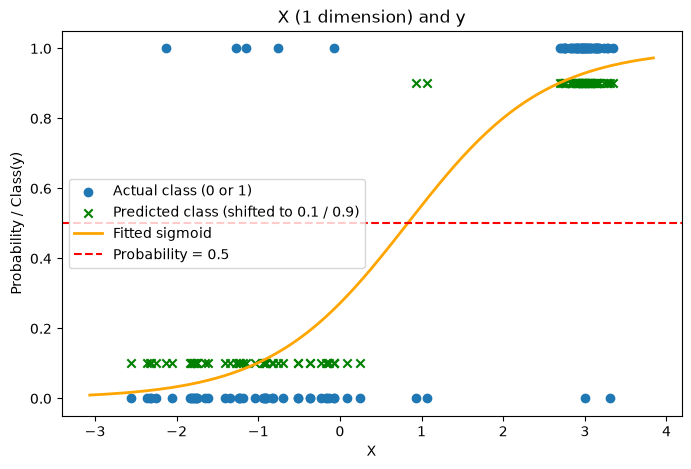

In [16]:
shifted_preds = np.where(custom_preds == 0, 0.1, 0.9)

plt.figure(figsize=(8, 5))
plt.scatter(X_1d, y, label="Actual class (0 or 1)")
plt.scatter(X_1d, shifted_preds, color="green", marker="x", label="Predicted class (shifted to 0.1 / 0.9)")
plt.plot(x_vals, sigmoid_vals, color="orange", linewidth=2, label="Fitted sigmoid")
plt.axhline(y=0.5, color="red", linestyle="--", label="Probability = 0.5")
plt.xlabel("X")
plt.ylabel("Probability / Class(y)")
plt.title("X (1 dimension) and y")
plt.legend()
plt.show()


## 2-Dimensional Logistic Regression & Decision Boundary

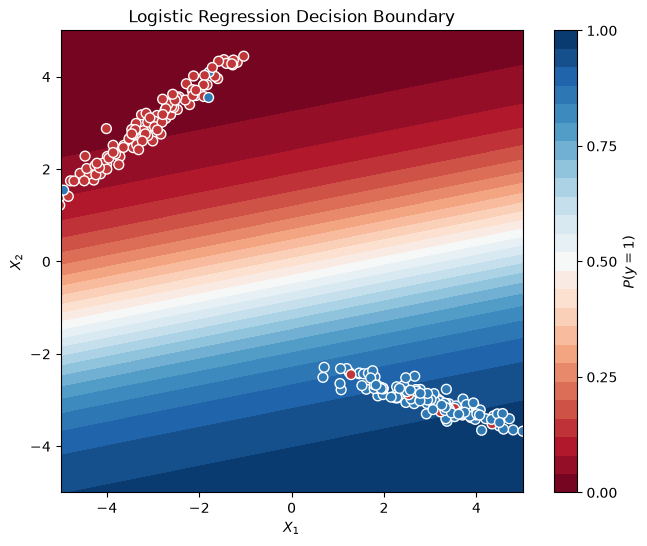

In [13]:
X_2d, y_2d = make_classification(
    n_features=2,
    n_redundant=0,
    n_samples=250,
    n_classes=2,
    n_clusters_per_class=1,
    flip_y=0.05,
    class_sep=3,
    random_state=43
)

clf = LogisticRegression()
clf.fit(X_2d, y_2d)

xx, yy = np.mgrid[-5:5:.01, -5:5:.01]
grid = np.c_[xx.ravel(), yy.ravel()]
probs = clf.predict_proba(grid)[:, 1].reshape(xx.shape)

f, ax = plt.subplots(figsize=(8, 6))
contour = ax.contourf(xx, yy, probs, 25, cmap="RdBu", vmin=0, vmax=1)
ax_c = f.colorbar(contour)
ax_c.set_label("$P(y = 1)$")
ax_c.set_ticks([0, .25, .5, .75, 1])

ax.scatter(
    X_2d[:, 0], X_2d[:, 1], c=y_2d, s=50,
    cmap="RdBu", vmin=-.2, vmax=1.2,
    edgecolor="white", linewidth=1
)

ax.set(
    aspect="equal",
    xlim=(-5, 5), ylim=(-5, 5),
    xlabel="$X_1$", ylabel="$X_2$"
)
plt.title("Logistic Regression Decision Boundary")
plt.show()
